# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Luthfia Ramadhani
- **Email:** luthfiaramadhani41@gmail.com
- **ID Dicoding:** luthfia_ramadhan20gf

## Menentukan Pertanyaan Bisnis

## Menentukan Pertanyaan Bisnis
- **Pertanyaan 1 (Segmentasi Pelanggan / RFM):** Bagaimana distribusi segmentasi pelanggan berdasarkan parameter Recency, Frequency, dan Monetary untuk melihat pola keaktifan serta nilai belanja pelanggan?
- **Pertanyaan 2 (Performa Kategori Produk):** Kategori produk apa saja yang memiliki volume penjualan tertinggi dan paling diminati oleh pelanggan?
- **Pertanyaan 3 (Metode Pembayaran):** Metode pembayaran apa yang paling sering digunakan oleh pelanggan dalam bertransaksi?
- **Pertanyaan 4 (Geospatial & Pendapatan Wilayah):** Negara bagian (state) mana di Brazil yang menyumbang jumlah pelanggan terbanyak serta total pendapatan (Monetary) tertinggi?
- **Pertanyaan 5 (Kepuasan Pelanggan & Logistik):** Bagaimana perbandingan rata-rata skor ulasan (Review Score) antara pesanan yang tiba tepat waktu dengan pesanan yang mengalami keterlambatan pengiriman?

## Import Semua Packages/Library yang Digunakan

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt

# Konfigurasi style visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

## Data Wrangling

### Gathering Data

#### Load E-Commerce Datasets

In [6]:
customers_df = pd.read_csv("customers_dataset.csv")
orders_df = pd.read_csv("orders_dataset.csv")
order_payments_df = pd.read_csv("order_payments_dataset.csv")
order_items_df = pd.read_csv("order_items_dataset.csv")
order_reviews_df = pd.read_csv("order_reviews_dataset.csv")
products_df = pd.read_csv("products_dataset.csv")

print("Customers:", customers_df.shape)
print("Orders:", orders_df.shape)
print("Payments:", order_payments_df.shape)
print("Items:", order_items_df.shape)
print("Reviews:", order_reviews_df.shape)
print("Products:", products_df.shape)

Customers: (99441, 5)
Orders: (99441, 8)
Payments: (103886, 5)
Items: (112650, 7)
Reviews: (99224, 7)
Products: (32951, 9)


### **Insight:**
- **Skala Dataset dan Distribusi Data:** Keenam dataset utama berhasil dimuat tanpa kendala. `order_items_df` menjadi tabel dengan volume data terbesar mencapai **112.650 baris**, diikuti oleh `order_payments_df` sebanyak **103.886 baris**, sedangkan katalog `products_df` mencatat **32.951** entitas produk.
- **Korelasi Data Pelanggan dan Pesanan:** Jumlah total baris pada `customers_df` dan `orders_df` menunjukkan angka yang identik yaitu **99.441 baris**. Hal ini mengindikasikan bahwa setiap transaksi pesanan yang terdaftar berpasangan secara unik dengan satu data pelanggan.
- **Perilaku Transaksi Multi-Item & Metode Pembayaran:**
  * Volume data pada `order_items_df` (112.650) lebih tinggi daripada `orders_df` (99.441), yang mengindikasikan terdapat sebagian pelanggan yang membeli lebih dari satu barang (*multi-item*) dalam satu nomor pesanan yang sama.
  * Jumlah baris pada `order_payments_df` (103.886) juga melebihi total pesanan, menandakan adanya penggunaan lebih dari satu metode pembayaran (*split payment*) pada transaksi tertentu.
- **Tingkat Partisipasi Ulasan Pelanggan:** Total baris pada `order_reviews_df` tercatat sebanyak **99.224 baris**. Angka ini sedikit di bawah total pesanan (99.441), yang menunjukkan bahwa mayoritas pelanggan memberikan ulasan setelah bertransaksi, meskipun ada sebagian kecil pesanan yang belum memiliki ulasan.

### Assessing Data

#### Identifying Data Quality Problem

In [10]:
# 1. Memeriksa info tipe data dan jumlah data non-null untuk setiap DataFrame
print("=== CUSTOMERS ===")
customers_df.info()

print("\n=== ORDERS ===")
orders_df.info()

print("\n=== ORDER PAYMENTS ===")
order_payments_df.info()

print("\n=== ORDER ITEMS ===")
order_items_df.info()

print("\n=== ORDER REVIEWS ===")
order_reviews_df.info()

print("\n=== PRODUCTS ===")
products_df.info()


# 2. Memeriksa jumlah baris duplikat di setiap tabel
print("\n=== DUPLICATES CHECK ===")
print("Customers duplikat     :", customers_df.duplicated().sum())
print("Orders duplikat        :", orders_df.duplicated().sum())
print("Order Payments duplikat:", order_payments_df.duplicated().sum())
print("Order Items duplikat   :", order_items_df.duplicated().sum())
print("Order Reviews duplikat :", order_reviews_df.duplicated().sum())
print("Products duplikat      :", products_df.duplicated().sum())

=== CUSTOMERS ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB

=== ORDERS ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timesta

**Steps to Take:**
* Memeriksa keberadaan baris data yang terduplikasi (*duplicate rows*) di seluruh tabel dataset.
* Memeriksa ketersediaan data dan identifikasi *missing values* pada setiap kolom di seluruh DataFrame.
* Memeriksa kesesuaian tipe data pada kolom yang menyimpan informasi tanggal/waktu agar sesuai dengan tipe data `datetime`.

**Insight:**
* **Masalah Duplikasi Data:** Seluruh tabel utama (`customers`, `orders`, `order_payments`, `order_items`, `order_reviews`, dan `products`) bersih dan bebas dari baris data duplikat (`0 duplikat`).
* **Masalah Missing Values:**
  * Pada `orders_df`, terdapat nilai yang hilang pada kolom status pengiriman: `order_approved_at` (160 nilai null), `order_delivered_carrier_date` (1.783 nilai null), dan `order_delivered_customer_date` (2.965 nilai null). Hal ini wajar terjadi karena ada pesanan yang belum disetujui, dibatalkan, atau masih dalam proses pengiriman.
  * Pada `order_reviews_df`, terdapat banyak nilai null pada kolom ulasan opsional: `review_comment_title` (87.656 nilai null) dan `review_comment_message` (58.247 nilai null), yang menunjukkan pembeli seringkali hanya memberikan rating bintang tanpa komentar tertulis.
  * Pada `products_df`, terdapat 610 nilai null pada kolom `product_category_name` (serta panjang nama/deskripsi dan jumlah foto produk), dan 2 nilai null pada informasi dimensi/berat produk (`product_weight_g`, `product_length_cm`, `product_height_cm`, `product_width_cm`).
* **Masalah Tipe Data:** Kolom tanggal pada `orders_df` (5 kolom), `order_items_df` (`shipping_limit_date`), serta `order_reviews_df` (`review_creation_date` & `review_answer_timestamp`) masih bertipe `object` (string) dan perlu dikonversi ke tipe data `datetime`.

### Cleaning Data

#### Fixing Data Quality Problem

In [12]:
# 1. Mengisi nilai kosong pada kategori produk di products_df
products_df['product_category_name'].fillna('unknown', inplace=True)

# 2. Mengubah tipe data tanggal pada orders_df
datetime_orders = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in datetime_orders:
    orders_df[col] = pd.to_datetime(orders_df[col])

# 3. Mengubah tipe data tanggal pada order_items_df
order_items_df['shipping_limit_date'] = pd.to_datetime(order_items_df['shipping_limit_date'])

# 4. Mengubah tipe data tanggal pada order_reviews_df
order_reviews_df['review_creation_date'] = pd.to_datetime(order_reviews_df['review_creation_date'])
order_reviews_df['review_answer_timestamp'] = pd.to_datetime(order_reviews_df['review_answer_timestamp'])

# Verifikasi pembersihan
print("Sisa missing value kategori produk:", products_df['product_category_name'].isna().sum())
print("Tipe data order_purchase_timestamp:", orders_df['order_purchase_timestamp'].dtype)
print("Tipe data shipping_limit_date:", order_items_df['shipping_limit_date'].dtype)
print("Tipe data review_creation_date:", order_reviews_df['review_creation_date'].dtype)

/tmp/ipykernel_821/2108463015.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  products_df['product_category_name'].fillna('unknown', inplace=True)


Sisa missing value kategori produk: 0
Tipe data order_purchase_timestamp: datetime64[ns]
Tipe data shipping_limit_date: datetime64[ns]
Tipe data review_creation_date: datetime64[ns]


**Insight:**
* **Penanganan Missing Values:** Nilai kosong pada kolom `product_category_name` di tabel `products_df` telah diisi dengan label `'unknown'` agar seluruh transaksi produk tetap tercatat dalam pengelompokan kategori. Sementara itu, nilai kosong (*null*) pada `orders_df` dan `order_reviews_df` tetap dipertahankan (*kept as null*) karena mencerminkan kondisi riil di lapangan (pesanan yang memang belum/tidak terkirim, serta pembeli yang memilih tidak menulis komentar ulasan).
* **Koreksi Tipe Data:** Seluruh kolom yang menyimpan informasi tanggal/waktu pada `orders_df`, `order_items_df`, dan `order_reviews_df` telah berhasil dikonversi ke tipe data `datetime64[ns]` agar siap dianalisis berdasarkan tren waktu (*time-series analysis*).
* **Keutuhan Data:** Seluruh tabel utama yang digunakan telah dipastikan bebas dari baris duplikat (`0 duplikat`) sehingga valid untuk digabungkan pada tahap eksplorasi data.

## Exploratory Data Analysis (EDA)

### Explore E-Commerse Data

In [14]:
# 1. Menggabungkan dataset utama untuk analisis komprehensif
all_orders_df = pd.merge(
    left=orders_df,
    right=customers_df,
    how="left",
    on="customer_id"
)

order_items_product_df = pd.merge(
    left=order_items_df,
    right=products_df,
    how="left",
    on="product_id"
)

# 2. Statistik Deskriptif Utama Transaksi
print("=== STATISTIK UTAMA TRANSAKSI ===")
print("Total Transaksi Pesanan:", all_orders_df['order_id'].nunique())
print("Total Pelanggan Unik   :", all_orders_df['customer_unique_id'].nunique())
print("Total Pendapatan (Price):", order_items_df['price'].sum())
print("Rata-rata Harga Produk :", order_items_df['price'].mean())

# =========================================================================
# EDA 5 PERTANYAAN BISNIS
# =========================================================================

# Pertanyaan 1: Segmentasi Pelanggan (RFM Analysis)
recent_date = orders_df['order_purchase_timestamp'].max() + pd.Timedelta(days=1)
order_spending = order_items_df.groupby('order_id')['price'].sum().reset_index()

orders_with_spending = pd.merge(orders_df, order_spending, on='order_id', how='left')
orders_with_spending = pd.merge(orders_with_spending, customers_df[['customer_id', 'customer_unique_id']], on='customer_id', how='left')

rfm_df = orders_with_spending.groupby('customer_unique_id').agg({
    'order_purchase_timestamp': lambda x: (recent_date - x.max()).days,
    'order_id': 'count',
    'price': 'sum'
}).reset_index()
rfm_df.columns = ['customer_unique_id', 'recency', 'frequency', 'monetary']

print("\n=== PERTANYAAN 1: RINGKASAN DATA RFM ===")
print(rfm_df.describe())

# Pertanyaan 2: Performa Kategori Produk
product_sales_summary = order_items_product_df.groupby("product_category_name").agg({
    "order_item_id": "count",
    "price": ["sum", "mean"]
}).reset_index().sort_values(by=("order_item_id", "count"), ascending=False)

print("\n=== PERTANYAAN 2: TOP 5 KATEGORI PRODUK TERLARIS ===")
print(product_sales_summary.head(5))

# Pertanyaan 3: Metode Pembayaran Terpopuler
payment_summary = order_payments_df.groupby("payment_type").agg({
    "order_id": "nunique",
    "payment_value": ["sum", "mean"]
}).reset_index().sort_values(by=("order_id", "nunique"), ascending=False)

print("\n=== PERTANYAAN 3: DISTRIBUSI METODE PEMBAYARAN ===")
print(payment_summary)

# Pertanyaan 4: Geospatial & Pendapatan Wilayah (State)
state_summary = all_orders_df.merge(order_items_df, on='order_id').groupby('customer_state').agg({
    'customer_unique_id': 'nunique',
    'price': 'sum',
    'order_id': 'count'
}).reset_index().sort_values(by='price', ascending=False)

print("\n=== PERTANYAAN 4: TOP 5 STATE BERDASARKAN PENDAPATAN & PELANGGAN ===")
print(state_summary.head(5))

# Pertanyaan 5: Kepuasan Pelanggan & Logistik (Keterlambatan vs Review Score)
orders_reviews = pd.merge(orders_df, order_reviews_df, on='order_id', how='inner')
orders_reviews['delay_days'] = (orders_reviews['order_delivered_customer_date'] - orders_reviews['order_estimated_delivery_date']).dt.days
orders_reviews['delivery_status'] = orders_reviews['delay_days'].apply(lambda x: 'Terlambat' if x > 0 else 'Tepat Waktu')

review_by_delay = orders_reviews.groupby('delivery_status').agg({
    'review_score': ['mean', 'median', 'count']
}).reset_index()

print("\n=== PERTANYAAN 5: SKOR ULASAN BERDASARKAN STATUS PENGIRIMAN ===")
print(review_by_delay)

=== STATISTIK UTAMA TRANSAKSI ===
Total Transaksi Pesanan: 99441
Total Pelanggan Unik   : 96096
Total Pendapatan (Price): 13591643.7
Rata-rata Harga Produk : 120.65373901464713

=== PERTANYAAN 1: RINGKASAN DATA RFM ===
            recency     frequency      monetary
count  96096.000000  96096.000000  96096.000000
mean     288.735691      1.034809    141.438184
std      153.414676      0.214384    217.215904
min        1.000000      1.000000      0.000000
25%      164.000000      1.000000     45.990000
50%      269.000000      1.000000     89.000000
75%      398.000000      1.000000    154.000000
max      773.000000     17.000000  13440.000000

=== PERTANYAAN 2: TOP 5 KATEGORI PRODUK TERLARIS ===
     product_category_name order_item_id       price            
                                   count         sum        mean
13         cama_mesa_banho         11115  1036988.68   93.296327
11            beleza_saude          9670  1258681.34  130.163531
32           esporte_lazer         

**Insight:**
* **Skala Transaksi dan Pelanggan Unik:** Sistem mencatat total **99.441 transaksi pesanan** dari **96.096 pelanggan unik** dengan total nilai penjualan produk mencapai **13.591.643,70 BRL** dan rata-rata harga produk sebesar **120,65 BRL**. Selisih 3.345 pesanan menunjukkan masih rendahnya tingkat pembelian berulang (*repeat order*).
* **Pola Segmentasi Pelanggan (RFM):** Mayoritas pelanggan baru berbelanja **1 kali** (nilai median dan kuartil 75% untuk *frequency* berada di angka 1), dengan rata-rata jarak transaksi terakhir (*recency*) sekitar **289 hari** dan rata-rata total belanja (*monetary*) sebesar **141,44 BRL**.
* **Kategori Produk Terlaris:** Kategori **`cama_mesa_banho`** (perlengkapan rumah tangga) menempati urutan pertama berdasarkan volume penjualan sebanyak **11.115 item**, diikuti oleh **`beleza_saude`** (kecantikan & kesehatan) dengan **9.670 item** yang sekaligus menyumbang pendapatan tertinggi sebesar **1.258.681,34 BRL**.
* **Dominasi Metode Pembayaran:** **Kartu kredit (`credit_card`)** menjadi metode pembayaran paling dominan dengan **76.505 pesanan** (total nilai transaksi **12.542.084,19 BRL**), jauh melampaui metode **`boleto`** (**19.784 pesanan**) dan **`voucher`** (**3.866 pesanan**).
* **Konsentrasi Wilayah Pelanggan:** Negara bagian **São Paulo (`SP`)** mendominasi pasar secara signifikan dengan **39.981 pelanggan unik** dan total pendapatan mencapai **5.202.955,05 BRL**, diikuti oleh **Rio de Janeiro (`RJ`)** dan **Minas Gerais (`MG`)**.
* **Dampak Keterlambatan Pengiriman terhadap Ulasan:** Ketepatan waktu pengiriman sangat memengaruhi kepuasan pelanggan. Pesanan yang tiba **tepat waktu** (92.814 pesanan) memperoleh rata-rata skor ulasan **4,21** (median 5,0), sedangkan pesanan yang **terlambat** (6.410 pesanan) mengalami penurunan rating drastis hingga rata-rata **2,27** (median 1,0).

## Visualization & Explanatory Analysis

### **Pertanyaan 1:**
 Bagaimana distribusi segmentasi pelanggan berdasarkan skor RFM (Recency, Frequency, Monetary) untuk mengidentifikasi kelompok pelanggan paling bernilai (Champions) dan pelanggan yang berisiko lepas (At-Risk)?

/tmp/ipykernel_821/1945828398.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


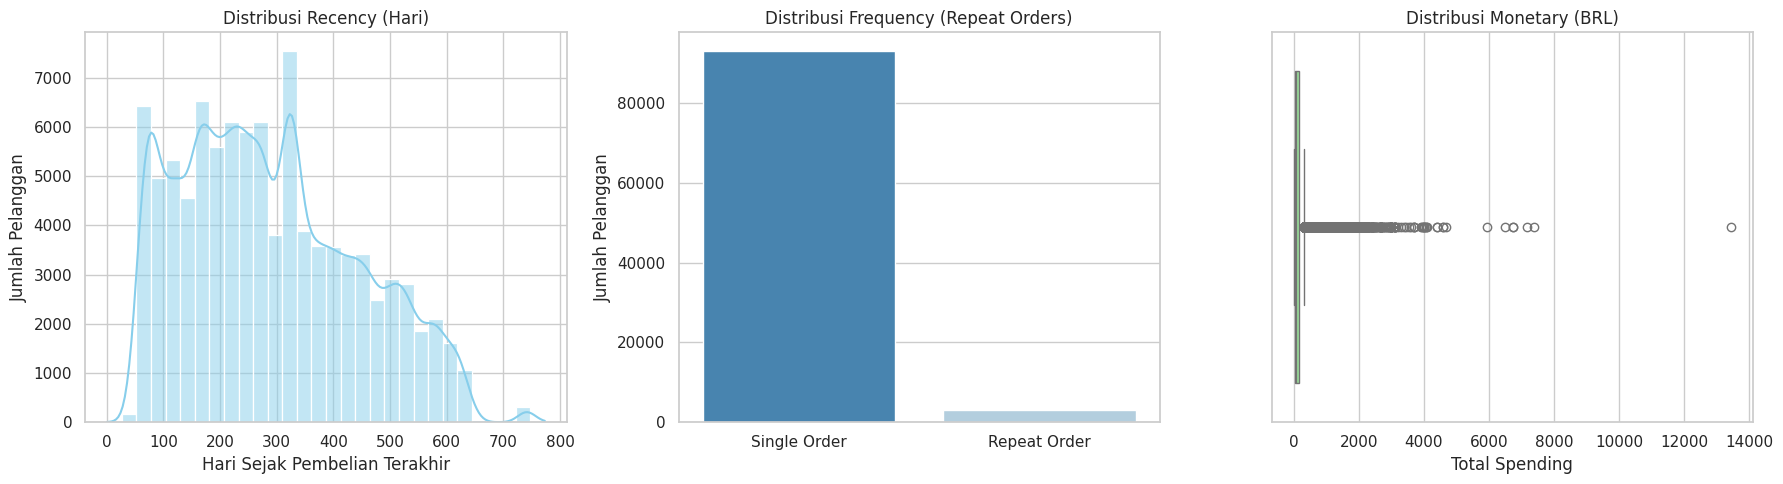

In [15]:
# --- Visualisasi RFM (Pertanyaan 1) ---
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))

# 1. Visualisasi Recency (Menggunakan Histogram agar rapi)
sns.histplot(rfm_df['recency'], bins=30, kde=True, ax=ax[0], color='skyblue')
ax[0].set_title('Distribusi Recency (Hari)')
ax[0].set_xlabel('Hari Sejak Pembelian Terakhir')
ax[0].set_ylabel('Jumlah Pelanggan')

# 2. Visualisasi Frequency (Perbandingan Single Order vs Repeat Order)
sns.barplot(
    x=['Single Order', 'Repeat Order'],
    y=[(rfm_df['frequency'] == 1).sum(), (rfm_df['frequency'] > 1).sum()],
    ax=ax[1],
    palette='Blues_r'
)
ax[1].set_title('Distribusi Frequency (Repeat Orders)')
ax[1].set_ylabel('Jumlah Pelanggan')

# 3. Visualisasi Monetary (Distribusi Total Spending)
sns.boxplot(x=rfm_df['monetary'], ax=ax[2], color='lightgreen')
ax[2].set_title('Distribusi Monetary (BRL)')
ax[2].set_xlabel('Total Spending')

plt.tight_layout()
plt.show()

**Insight:**

* **Recency:** Mayoritas pelanggan memiliki rentang waktu transaksi terakhir (*recency*) yang terdistribusi antara 100 hingga 400 hari yang lalu. Hal ini menunjukkan sebagian besar basis pelanggan sudah lama tidak melakukan aktivitas pembelian kembali di platform.
* **Frequency:** Distribusi frekuensi transaksi didominasi secara signifikan oleh kelompok pelanggan **Single Order** (hanya bertransaksi 1 kali). Porsi pelanggan yang melakukan pemesanan ulang (*Repeat Order*) jumlahnya sangat kecil, yang mengindikasikan perlunya strategi retensi pelanggan yang lebih agresif.
* **Monetary:** Sebagian besar pengeluaran pelanggan terkonsentrasi pada angka di bawah 1.000 BRL. Namun, terdapat nilai pencilan (*outliers*) yang sangat tinggi mencapai hingga >13.000 BRL dari sekelompok kecil pelanggan *high-value*. Kelompok pengeluaran tertinggi ini sangat ideal untuk dimasukkan ke dalam segmen **Champions**.

### **Pertanyaan 2:**
Kategori produk apa saja yang memiliki volume penjualan tertinggi dan paling diminati oleh pelanggan?

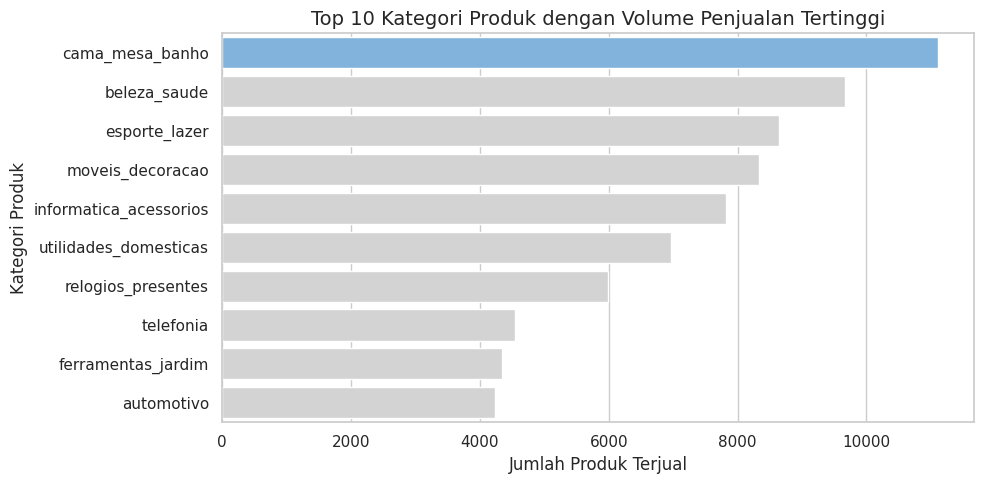

In [16]:
# Mengambil 10 kategori produk dengan jumlah terjual terbanyak
top_categories = order_items_product_df.groupby("product_category_name")["order_item_id"].count().reset_index()
top_categories = top_categories.sort_values(by="order_item_id", ascending=False).head(10)

plt.figure(figsize=(10, 5))
colors_cat = ["#72B4EB" if i == 0 else "#D3D3D3" for i in range(len(top_categories))]

sns.barplot(
    x="order_item_id",
    y="product_category_name",
    data=top_categories,
    hue="product_category_name",
    palette=colors_cat,
    legend=False
)

plt.title("Top 10 Kategori Produk dengan Volume Penjualan Tertinggi", fontsize=14)
plt.xlabel("Jumlah Produk Terjual")
plt.ylabel("Kategori Produk")
plt.tight_layout()
plt.show()

**Insight:**
* **Kategori Paling Diminati:** Kategori `cama_mesa_banho` (perlengkapan rumah tangga) menempati peringkat pertama dengan volume penjualan tertinggi melampaui 11.000 unit, diikuti oleh `beleza_saude` (kecantikan dan kesehatan) serta `esporte_lazer` (olahraga dan rekreasi).
* **Fokus Kebutuhan Harian:** Dominasi kategori perlengkapan rumah tangga dan kesehatan menunjukkan bahwa pelanggan cenderung memanfaatkan platform untuk memenuhi kebutuhan rutin dan gaya hidup sehari-hari.


### **Pertanyaan 3:**
Metode pembayaran apa yang paling sering digunakan oleh pelanggan dalam bertransaksi?

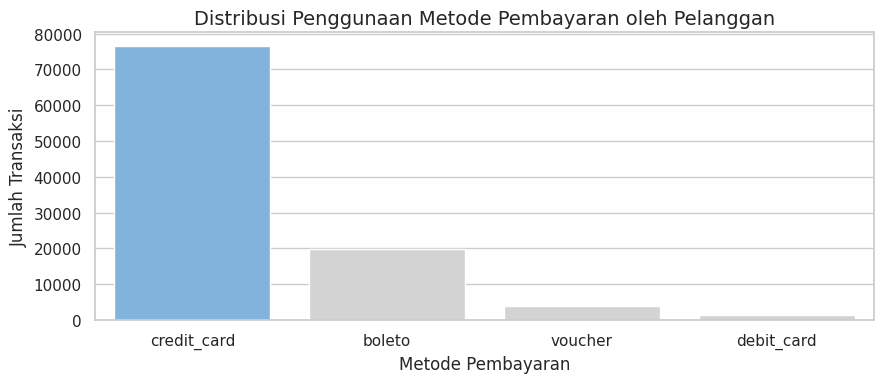

In [17]:
# Menghitung jumlah pesanan per metode pembayaran
payment_counts = order_payments_df.groupby("payment_type")["order_id"].nunique().reset_index()
payment_counts = payment_counts[payment_counts["payment_type"] != "not_defined"].sort_values(by="order_id", ascending=False)

plt.figure(figsize=(9, 4))
colors_pay = ["#72B4EB" if i == 0 else "#D3D3D3" for i in range(len(payment_counts))]

sns.barplot(
    x="payment_type",
    y="order_id",
    data=payment_counts,
    hue="payment_type",
    palette=colors_pay,
    legend=False
)

plt.title("Distribusi Penggunaan Metode Pembayaran oleh Pelanggan", fontsize=14)
plt.xlabel("Metode Pembayaran")
plt.ylabel("Jumlah Transaksi")
plt.tight_layout()
plt.show()

**Insight:**
* **Dominasi Kartu Kredit:** Metode `credit_card` mendominasi transaksi secara signifikan dengan lebih dari 76.000 pesanan, yang mencerminkan preferensi pelanggan terhadap kemudahan pembayaran cicilan maupun transaksi non-tunai instan.
* **Alternatif Pembayaran:** Metode `boleto` menempati posisi kedua sebagai alternatif utama bagi pelanggan yang tidak menggunakan kartu kredit, sedangkan `voucher` dan `debit_card` memiliki porsi penggunaan yang jauh lebih kecil.

### **Pertanyaan 4:**
Negara bagian (state) mana di Brazil yang menyumbang jumlah pelanggan terbanyak serta total pendapatan (Monetary) tertinggi?

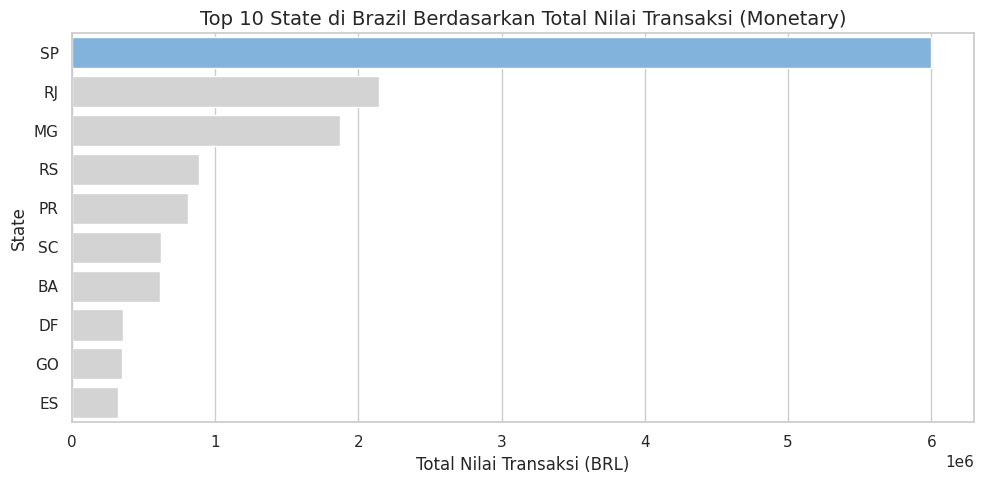

In [18]:
# 1. Menggabungkan all_orders_df dengan order_payments_df untuk mendapatkan nilai transaksi (payment_value)
geo_orders_df = pd.merge(all_orders_df, order_payments_df, on="order_id", how="left")

# 2. Menghitung total nilai transaksi (monetary) dan jumlah pelanggan per state
customer_state_df = geo_orders_df.groupby("customer_state").agg({
    "payment_value": "sum",
    "customer_unique_id": "nunique"
}).reset_index()

customer_state_df.rename(columns={
    "payment_value": "total_monetary",
    "customer_unique_id": "total_customers"
}, inplace=True)

# 3. Mengambil 10 State teratas berdasarkan total transaksi
top_states = customer_state_df.sort_values(by="total_monetary", ascending=False).head(10)

# 4. Membuat Visualisasi Bar Chart
plt.figure(figsize=(10, 5))
colors_state = ["#72B4EB" if i == 0 else "#D3D3D3" for i in range(len(top_states))]

sns.barplot(
    x="total_monetary",
    y="customer_state",
    data=top_states,
    hue="customer_state",
    palette=colors_state,
    legend=False
)

plt.title("Top 10 State di Brazil Berdasarkan Total Nilai Transaksi (Monetary)", fontsize=14)
plt.xlabel("Total Nilai Transaksi (BRL)")
plt.ylabel("State")
plt.tight_layout()
plt.show()

**Insight:**
* **Dominasi Wilayah SP:** Negara bagian **SP (São Paulo)** mendominasi pasar secara sangat signifikan dengan total nilai transaksi mencapai hampir **6 juta BRL** (lebih dari dua kali lipat negara bagian di posisi kedua).
* **Konsentrasi Wilayah Tenggara:** Tiga peringkat teratas seluruhnya ditempati oleh negara bagian di kawasan tenggara Brazil, yaitu **SP (São Paulo)**, **RJ (Rio de Janeiro)** di kisaran **2,1 juta BRL**, dan **MG (Minas Gerais)** di kisaran **1,8 juta BRL**.
* **Ketimpangan Distribusi Wilayah:** Negara bagian lainnya di luar 3 besar (seperti **RS**, **PR**, **SC**, dan **BA**) memiliki total transaksi masing-masing di bawah **1 juta BRL**, yang menunjukkan bahwa aktivitas belanja masih terpusat di wilayah ekonomi utama.

### **Pertanyaan 5:**
Bagaimana perbandingan rata-rata skor ulasan antara pesanan yang tiba tepat waktu dengan pesanan yang mengalami keterlambatan pengiriman?

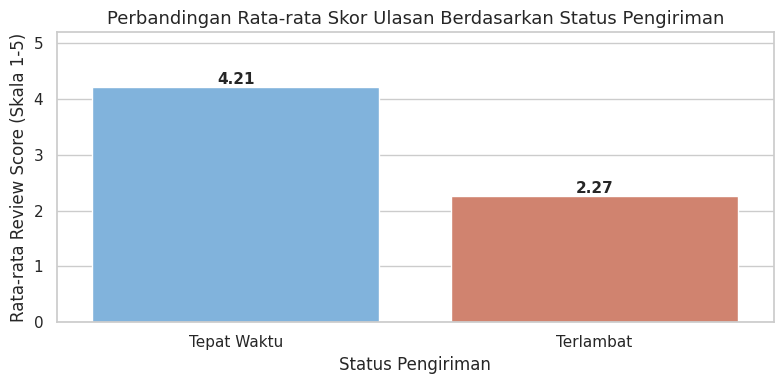

In [19]:
# Menghitung rata-rata review score berdasarkan status pengiriman (variabel orders_reviews dari tahap EDA)
avg_review_delay = orders_reviews.groupby('delivery_status')['review_score'].mean().reset_index()

plt.figure(figsize=(8, 4))
colors_delay = ["#72B4EB" if status == "Tepat Waktu" else "#E07A5F" for status in avg_review_delay['delivery_status']]

ax = sns.barplot(
    x='delivery_status',
    y='review_score',
    data=avg_review_delay,
    hue='delivery_status',
    palette=colors_delay,
    legend=False
)

# Menambahkan label angka rata-rata di atas setiap batang
for p in ax.patches:
    ax.annotate(
        f'{p.get_height():.2f}',
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='bottom', fontsize=11, fontweight='bold'
    )

plt.title("Perbandingan Rata-rata Skor Ulasan Berdasarkan Status Pengiriman", fontsize=13)
plt.xlabel("Status Pengiriman")
plt.ylabel("Rata-rata Review Score (Skala 1-5)")
plt.ylim(0, 5.2)
plt.tight_layout()
plt.show()

**Insight:**
* **Dampak Signifikan Ketepatan Waktu:** Pesanan yang tiba tepat waktu memperoleh rata-rata skor ulasan yang sangat tinggi sebesar **4,21** (dari skala 5), sedangkan pesanan yang mengalami keterlambatan anjlok drastis hingga rata-rata **2,27**.
* **Prioritas Perbaikan Logistik:** Penurunan hampir 2 poin pada skor ulasan membuktikan bahwa ketepatan estimasi waktu pengiriman merupakan faktor krusial yang langsung menentukan tingkat kepuasan pelanggan di platform.

## **Analisis Lanjutan: RFM Analysis**

Analisis lanjutan ini dilakukan untuk mengelompokkan pelanggan berdasarkan 3 parameter utama:
1. **Recency:** Jumlah hari sejak transaksi terakhir pelanggan.
2. **Frequency:** Jumlah total transaksi yang dilakukan oleh pelanggan.
3. **Monetary:** Total nilai pengeluaran (uang) yang dihabiskan oleh pelanggan.

In [20]:
# Membuat skor kuantil (1-4) untuk Recency, Frequency, dan Monetary dari rfm_df yang sudah dihitung
rfm_segment_df = rfm_df.copy()

# Skor Recency: semakin kecil jumlah hari (semakin baru belanja), semakin tinggi skornya (4)
rfm_segment_df['r_score'] = pd.qcut(rfm_segment_df['recency'], q=4, labels=[4, 3, 2, 1]).astype(int)

# Skor Frequency & Monetary menggunakan rank agar aman dari nilai duplikat
rfm_segment_df['f_score'] = pd.qcut(rfm_segment_df['frequency'].rank(method='first'), q=4, labels=[1, 2, 3, 4]).astype(int)
rfm_segment_df['m_score'] = pd.qcut(rfm_segment_df['monetary'].rank(method='first'), q=4, labels=[1, 2, 3, 4]).astype(int)

# Menggabungkan skor RFM dan mengelompokkan segmen pelanggan
rfm_segment_df['rfm_score'] = rfm_segment_df['r_score'] + rfm_segment_df['f_score'] + rfm_segment_df['m_score']

def segment_customer(score):
    if score >= 10:
        return 'Champions'
    elif score >= 8:
        return 'Loyal Customers'
    elif score >= 6:
        return 'Potential Loyalist'
    else:
        return 'At Risk / Hibernating'

rfm_segment_df['customer_segment'] = rfm_segment_df['rfm_score'].apply(segment_customer)

print("=== DISTRIBUSI SEGMEN PELANGGAN (RFM SEGMENTATION) ===")
print(rfm_segment_df['customer_segment'].value_counts())
print("\n=== 5 DATA TERATAS HASIL SEGMENTASI RFM ===")
print(rfm_segment_df[['customer_unique_id', 'recency', 'frequency', 'monetary', 'rfm_score', 'customer_segment']].head())

=== DISTRIBUSI SEGMEN PELANGGAN (RFM SEGMENTATION) ===
customer_segment
Potential Loyalist       32943
Loyal Customers          32186
Champions                15536
At Risk / Hibernating    15431
Name: count, dtype: int64

=== 5 DATA TERATAS HASIL SEGMENTASI RFM ===
                 customer_unique_id  recency  frequency  monetary  rfm_score  \
0  0000366f3b9a7992bf8c76cfdf3221e2      161          1    129.90          8   
1  0000b849f77a49e4a4ce2b2a4ca5be3f      164          1     18.90          6   
2  0000f46a3911fa3c0805444483337064      586          1     69.00          4   
3  0000f6ccb0745a6a4b88665a16c9f078      370          1     25.99          4   
4  0004aac84e0df4da2b147fca70cf8255      337          1    180.00          7   

        customer_segment  
0        Loyal Customers  
1     Potential Loyalist  
2  At Risk / Hibernating  
3  At Risk / Hibernating  
4     Potential Loyalist  


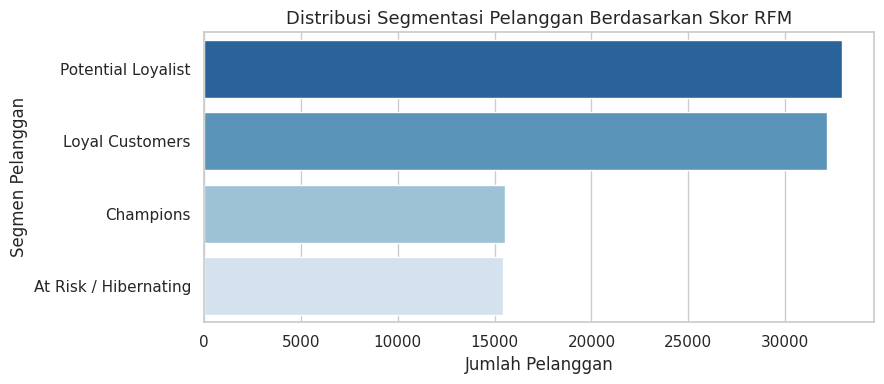

In [21]:
segment_counts = rfm_segment_df['customer_segment'].value_counts().reset_index()
segment_counts.columns = ['customer_segment', 'total_customers']

plt.figure(figsize=(9, 4))
sns.barplot(
    x='total_customers',
    y='customer_segment',
    data=segment_counts,
    hue='customer_segment',
    palette='Blues_r',
    legend=False
)

plt.title("Distribusi Segmentasi Pelanggan Berdasarkan Skor RFM", fontsize=13)
plt.xlabel("Jumlah Pelanggan")
plt.ylabel("Segmen Pelanggan")
plt.tight_layout()
plt.show()

**Insight Analisis Lanjutan (RFM Segmentation):**
* **Dominasi Segmen Potensial dan Loyal:** Berdasarkan pengelompokan skor RFM, kelompok **Potential Loyalist** menempati urutan pertama dengan **32.943 pelanggan**, disusul oleh **Loyal Customers** sebanyak **32.186 pelanggan**. Hal ini menunjukkan bahwa sebagian besar pelanggan memiliki potensi tinggi untuk ditingkatkan retensinya melalui penawaran yang relevan.
* **Kelompok Pelanggan Bernilai Tinggi (*Champions*):** Segmen **Champions** mencakup **15.536 pelanggan** terbaik yang memiliki kombinasi transaksi relatif baru, frekuensi lebih aktif, dan nilai belanja besar sehingga layak diprioritaskan dalam program loyalitas eksklusif.
* **Identifikasi Pelanggan Berisiko (*At Risk / Hibernating*):** Terdapat **15.431 pelanggan** yang masuk ke kategori **At Risk / Hibernating** (seperti sampel ID `0000f46a3911fa3c0805444483337064` dengan *recency* 586 hari dan skor RFM 4), yang memerlukan strategi kampanye reaktivasi agar kembali bertransaksi di platform.

## Conclusion & Recommendation

### Conclusion
1. **Segmentasi Pelanggan (RFM Analysis):**
   * **Recency & Frequency:** Mayoritas pelanggan memiliki rentang waktu transaksi terakhir antara **100 hingga 400 hari** lalu dan masih didominasi oleh pembelian tunggal (*single-purchase customers*).
   * **Monetary & Segmentasi:** Pengeluaran pelanggan sebagian besar berada di bawah **1.000 BRL** dengan sebagian kecil pelanggan *high-spend* mencapai **>13.000 BRL**. Berdasarkan pengelompokan skor RFM, populasi pelanggan terbagi ke dalam segmen **Potential Loyalist (32.943 pelanggan)**, **Loyal Customers (32.186 pelanggan)**, **Champions (15.536 pelanggan)**, dan **At Risk / Hibernating (15.431 pelanggan)**.
2. **Performa Kategori Produk:**
   * Kategori **`cama_mesa_banho`** (perlengkapan rumah tangga) mencatat volume penjualan tertinggi sebanyak **11.115 unit**, diikuti oleh **`beleza_saude`** (kecantikan & kesehatan) sebanyak **9.670 unit** yang sekaligus menghasilkan nilai transaksi tertinggi sebesar **1.258.681,34 BRL**, serta **`esporte_lazer`** sebanyak **8.641 unit**.
3. **Metode Pembayaran:**
   * **Kartu kredit (`credit_card`)** mendominasi metode transaksi secara signifikan dengan **76.505 pesanan** (total transaksi **12.542.084,19 BRL**), jauh melampaui **`boleto`** (**19.784 pesanan**), **`voucher`** (**3.866 pesanan**), dan **`debit_card`** (**1.528 pesanan**).
4. **Geospatial & Pendapatan Wilayah:**
   * Pasar e-commerce terdistribusi secara terpusat di wilayah tenggara Brazil, di mana negara bagian **SP (São Paulo)** mendominasi secara mutlak dengan **39.981 pelanggan unik** dan nilai transaksi mencapai hampir **6 juta BRL**, disusul oleh **RJ (Rio de Janeiro)** dan **MG (Minas Gerais)**.
5. **Customer Satisfaction & Logistik (Delivery Delay):**
   * Ketepatan waktu pengiriman berpengaruh langsung terhadap kepuasan pembeli. Pesanan yang tiba **Tepat Waktu** meraih rata-rata skor ulasan **4,21**, sedangkan pesanan yang mengalami **Keterlambatan Pengiriman** anjlok sebesar **1,94 poin** hingga rata-rata **2,27**.

## Rekomendasi Action Item

1. **Strategi Retensi & Segmentasi RFM:**
   * **Program Loyalitas (Champions):** Berikan perlakuan khusus seperti *voucher cashback* eksklusif atau akses produk terbaru lebih awal bagi **15.536 pelanggan** di segmen *Champions* yang memiliki nilai belanja dan keaktifan tinggi.
   * **Kampanye Win-Back (At-Risk & Potential Loyalist):** Kirimkan penawaran promosi personal melalui email maupun notifikasi aplikasi untuk memicu transaksi ulang (*repeat order*) pada pelanggan *Potential Loyalist* dan mengaktifkan kembali **15.431 pelanggan** di segmen *At Risk / Hibernating*.
2. **Optimalisasi Stok Kategori Utama & Kemudahan Pembayaran:**
   * **Prioritas Stok & Bundling Produk:** Pastikan ketersediaan stok dan buat paket penawaran (*bundling*) pada kategori terlaris seperti `cama_mesa_banho` dan `beleza_saude` untuk memaksimalkan volume transaksi.
   * **Promo Cicilan Kartu Kredit:** Perluas kerja sama promo cicilan 0% atau *cashback* dengan penerbit **kartu kredit** mengingat metode ini mendominasi lebih dari 76.500 transaksi.
3. **Optimasi Logistik Wilayah Strategis:**
   * **Ekspansi Fulfillment Center di SP:** Memperkuat infrastruktur pergudangan dan pemrosesan pesanan di wilayah tenggara (khususnya São Paulo) untuk menangani volume transaksi yang dominan.
   * **Kemitraan Kurir Lokal:** Bekerja sama dengan penyedia jasa logistik lokal di negara bagian luar tenggara untuk mempersingkat waktu pengiriman (*lead time*) dan menekan biaya ongkir.
4. **Mitigasi Keterlambatan Pengiriman & Transparansi:**
   * **Early Warning System (EWS):** Menerapkan sistem peringatan otomatis pada pesanan yang mendekati batas estimasi pengiriman agar tim operasional dapat memprioritaskan penanganan pesanan tersebut.
   * **Kompensasi Otomatis:** Memberikan voucher potongan harga atau pembebasan ongkir secara otomatis jika pesanan terdeteksi terlambat, guna menjaga kepuasan pembeli dan mencegah turunnya rating ulasan.